In [2]:
# Import TensorFlow for building and training the CNN model
import tensorflow as tf

# Import NumPy for numerical operations
import numpy as np

# Import Matplotlib for visualizing training results
import matplotlib.pyplot as plt

# Import Keras layers and Sequential model
from tensorflow.keras import layers, models

# Import OS for creating folders and saving the model
import os

# Load the preprocessed MNIST dataset
data = np.load("../data/processed/mnist_preprocessed.npz")

# Extract training images and their labels
X_train = data["X_train"]
y_train = data["y_train"]

# Extract validation images and their labels
X_val = data["X_val"]
y_val = data["y_val"]

# Extract testing images and their labels
X_test = data["X_test"]
y_test = data["y_test"]

# Display dataset shapes
print("Training data:", X_train.shape, y_train.shape)
print("Validation data:", X_val.shape, y_val.shape)
print("Testing data:", X_test.shape, y_test.shape)

Training data: (54000, 28, 28, 1) (54000,)
Validation data: (6000, 28, 28, 1) (6000,)
Testing data: (10000, 28, 28, 1) (10000,)


In [3]:
# Create a Sequential CNN model
model = models.Sequential([

    # Define input shape for grayscale images
    layers.Input(shape=(28, 28, 1)),

    # First convolution layer: Detect basic image patterns
    layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),

    # Reduce feature map dimensions
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Second convolution layer: Learn more complex patterns
    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),

    # Reduce feature map dimensions again
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Convert feature maps into a one-dimensional vector
    layers.Flatten(),

    # Fully connected layer for learning digit features
    layers.Dense(128, activation="relu"),

    # Output probabilities for 10 digit classes (0-9)
    layers.Dense(10, activation="softmax")
])

# Display the model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Configure the model before training
model.compile(

    # Adam optimizer updates model weights to reduce errors
    optimizer="adam",

    # Calculate loss for integer digit labels (0-9)
    loss="sparse_categorical_crossentropy",

    # Track classification accuracy during training
    metrics=["accuracy"]
)

# Confirm that model compilation is complete
print("Model compiled successfully!")

Model compiled successfully!


In [5]:
# Stop training if validation loss does not improve
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train the CNN model
history = model.fit(

    # Training images
    X_train,

    # Correct training labels
    y_train,

    # Maximum number of training epochs
    epochs=15,

    # Number of images processed in one batch
    batch_size=128,

    # Validation data used to monitor model performance
    validation_data=(X_val, y_val),

    # Apply early stopping
    callbacks=[early_stopping]
)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - accuracy: 0.9337 - loss: 0.2238 - val_accuracy: 0.9785 - val_loss: 0.0753
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 40ms/step - accuracy: 0.9821 - loss: 0.0583 - val_accuracy: 0.9805 - val_loss: 0.0652
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 38ms/step - accuracy: 0.9877 - loss: 0.0408 - val_accuracy: 0.9823 - val_loss: 0.0608
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - accuracy: 0.9901 - loss: 0.0317 - val_accuracy: 0.9865 - val_loss: 0.0464
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - accuracy: 0.9927 - loss: 0.0237 - val_accuracy: 0.9873 - val_loss: 0.0424
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - accuracy: 0.9940 - loss: 0.0193 - val_accuracy: 0.9870 - val_loss: 0.0457
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - accuracy: 0.9950 - loss: 0.0153 - val_accuracy: 0.9845 - val_loss: 0.0583
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - accuracy: 0.9963 - loss: 0.0121 - 

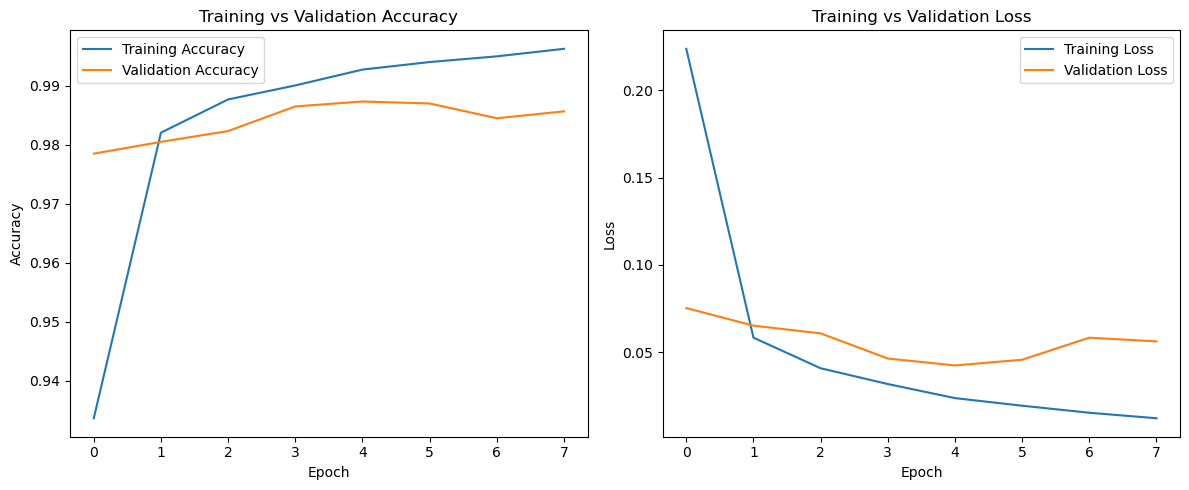

In [6]:
# Create a figure containing two plots
plt.figure(figsize=(12, 5))

# Plot training and validation accuracy
plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

# Adjust layout and display both graphs
plt.tight_layout()
plt.show()

In [7]:
# Create the models folder if it does not exist
os.makedirs("../models", exist_ok=True)

# Save the trained CNN model in Keras format
model.save("../models/mnist_cnn.keras")

# Confirm that the model was saved
print("CNN model saved successfully!")

CNN model saved successfully!
